<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />

<h1>Exploratory Data Analysis</h1>
DAT-7470 - Business Analysis with Structured Data<br>
Script 03 - Completed Notebook<br><br>
Based on the course script by Chase Kusterer, Hult International Business School<br>
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />

In this session we explore how each feature affects the price of a diamond engagement ring.
Remember: <strong>correlation does not imply causation</strong> (see <a href="https://hbr.org/2015/06/beware-spurious-correlations">this HBR article</a>).

~~~
Some people feel the rain. Others just get wet.
    - Bob Marley
~~~

<strong>Google Colab:</strong> upload <code>diamonds.xlsx</code> with the folder icon on the left (Files &rarr; Upload), or run the first code cell and pick the file when the upload button appears.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part I: Exploring Individual Features</h2>
<h4>a) Import the diamonds dataset with proper data types.</h4>

In [1]:
# importing packages
import pandas            as pd  # data science essentials
import matplotlib.pyplot as plt # NEW: data visualization essentials
import seaborn           as sns # NEW: enhanced data visualization
import statsmodels.formula.api as smf # NEW: linear modeling
import os
import warnings


# suppressing warnings
warnings.filterwarnings("ignore")


# specifying a file (works in Google Colab and in local Jupyter)
file = None
for path in ["./diamonds.xlsx", "./datasets/diamonds.xlsx", "/content/diamonds.xlsx"]:
    if os.path.exists(path):
        file = path
        break

if file is None:                       # not found -> open Colab's upload button
    from google.colab import files
    uploaded = files.upload()          # choose diamonds.xlsx from your computer
    file = list(uploaded.keys())[0]


# converting data types with a dictionary
data_types = {"channel" : str,
              "store"   : str}


# reading the file into Python through pandas
diamonds = pd.read_excel(io         = file      ,
                         dtype      = data_types,
                         usecols    = range(1, 8)) # omitting Obs


# outputting the first 5 rows of the dataset
diamonds.head(n = 5)

,carat,color,clarity,cut,channel,store,price
0,0.32,3,7,0,0,7,1375
1,0.35,5,7,1,0,7,1680
2,0.40,4,7,1,0,7,2245
3,0.59,5,7,0,0,3,2495
4,0.72,7,8,0,0,8,2699


<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h3>Histograms</h3>
Our goal is to understand how carat, color, clarity and cut contribute to price. Before building a model, we explore the data, paying close attention to <em>price</em> because that is what the model will predict.

In [2]:
# documentation for making histplot
help(sns.histplot)

Help on function histplot in module seaborn.distributions:

histplot(
    data=None,
    *,
    x=None,
    y=None,
    hue=None,
    weights=None,
    stat='count',
    bins='auto',
    binwidth=None,
    binrange=None,
    discrete=None,
    cumulative=False,
    common_bins=True,
    common_norm=True,
    multiple='layer',
    element='bars',
    fill=True,
    shrink=1,
    kde=False,
    kde_kws=None,
    line_kws=None,
    thresh=0,
    pthresh=None,
    pmax=None,
    cbar=False,
    cbar_ax=None,
    cbar_kws=None,
    palette=None,
    hue_order=None,
    hue_norm=None,
    color=None,
    log_scale=None,
    legend=True,
    ax=None,
    **kwargs
)
    Plot univariate or bivariate histograms to show distributions of datasets.

    A histogram is a classic visualization tool that represents the distribution
    of one or more variables by counting the number of observations that fall within
    discrete bins.

    This function can normalize the statistic computed within each 

<strong>b) Analyze the distribution of price.</strong><br>
Is <em>price</em> normally distributed? Is it skewed positive or negative?

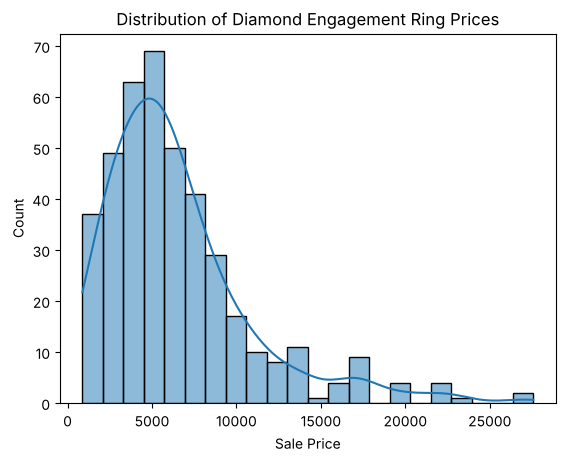

In [3]:
# developing a histogram using HISTPLOT
sns.histplot(data   = diamonds,
             x      = 'price',
             kde    = True)


# title and axis labels
plt.title(label   = "Distribution of Diamond Engagement Ring Prices")
plt.xlabel(xlabel = "Sale Price") # avoiding using dataset labels
plt.ylabel(ylabel = "Count")


# displaying the histogram
plt.show()

In [4]:
# checking the shape of the distribution with numbers
print(f"Mean     : ${diamonds['price'].mean():,.0f}")
print(f"Median   : ${diamonds['price'].median():,.0f}")
print(f"Skewness : {diamonds['price'].skew():.2f}  (0 = symmetric, > 0 = skewed positive)")

Mean     : $6,488
Median   : $5,550
Skewness : 1.73  (0 = symmetric, > 0 = skewed positive)


<strong>Answer:</strong> No, price is **not normally distributed**. It is **skewed positive** (to the right): most diamonds cost between about \$2,000 and \$9,000, and a long tail of a few expensive stones reaches \$27,575. The mean (\$6,488) is above the median (\$5,550), and the skewness is about 1.7, which confirms the right skew. We will deal with this later in the course.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h3>Binning Bias</h3>
Run the following code to generate a histogram for diamond color.

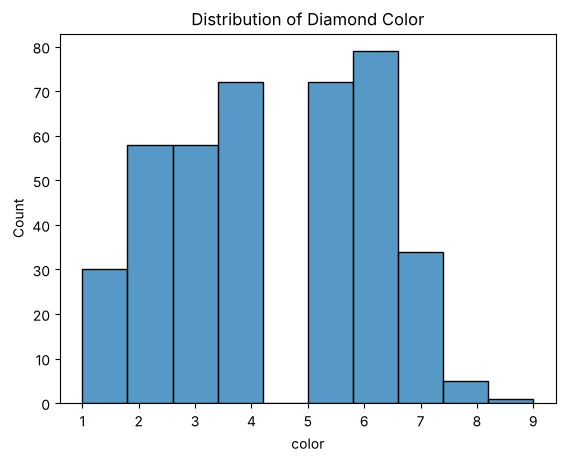

In [5]:
# diamond color distribution
sns.histplot(x    = 'color',
             data = diamonds)


# title and labels
plt.title (label  = 'Distribution of Diamond Color')


# displaying the plot
plt.show()

The default settings choose the number of bins automatically. Color only has 9 possible values (1 to 9), so the default bins can merge two grades into one bar or leave gaps. This gives a misleading picture. That is **binning bias**.

<h4>c) Adjust the code below to avoid binning bias.</h4>
Set one bin for each of the 9 color grades.

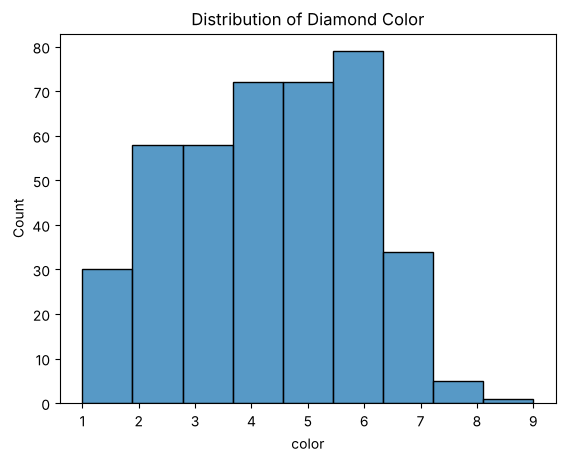

In [6]:
# diamond color distribution
sns.histplot(x    = 'color',
             data = diamonds,
             bins = 9)       # one bin per color grade (1 to 9)


# title and labels
plt.title (label  = 'Distribution of Diamond Color')


# displaying the plot
plt.show()

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h4>d) Develop histograms for carat, clarity, and cut.</h4>
Are any of the features normally distributed? Did the number of bins need to be adjusted for any of the features?

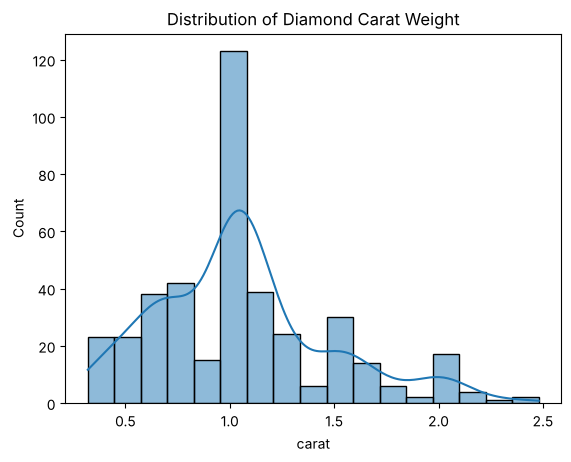

In [7]:
# diamond carat distribution (continuous feature, default bins are fine)
sns.histplot(x    = 'carat',
             data = diamonds,
             kde  = True)


# title and labels
plt.title (label  = 'Distribution of Diamond Carat Weight')


# displaying the plot
plt.show()

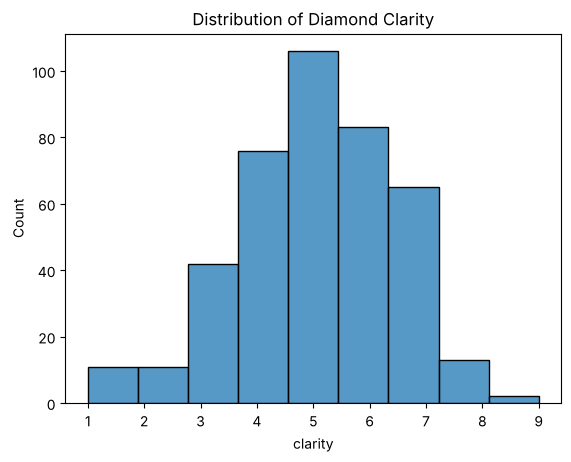

In [8]:
# diamond clarity distribution
sns.histplot(x    = 'clarity',
             data = diamonds,
             kde  = False,
             bins = 9)       # one bin per clarity grade (1 to 9)


# title and labels
plt.title (label  = 'Distribution of Diamond Clarity')


# displaying the plot
plt.show()

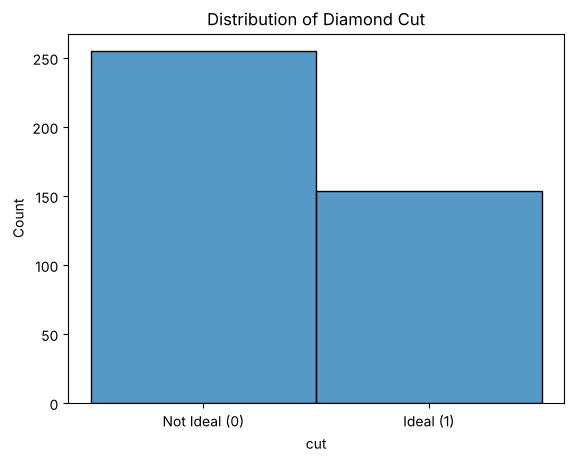

In [9]:
# diamond cut distribution
sns.histplot(x        = 'cut',
             data     = diamonds,
             discrete = True)   # only two values: 0 = Not Ideal, 1 = Ideal


# title and labels
plt.title (label  = 'Distribution of Diamond Cut')
plt.xticks(ticks  = [0, 1], labels = ['Not Ideal (0)', 'Ideal (1)'])


# displaying the plot
plt.show()

<strong>Answer:</strong>

* **Carat:** roughly bell-shaped, with a peak near 1 carat, but with a slight positive skew (a few stones above 2 carats). Carat is continuous, so the default bins work and no change was needed.
* **Clarity:** the closest to **normal**, with one peak at grade 5 and fewer values on both sides. The bins **did** need to be set to 9 (one per grade) to avoid binning bias.
* **Cut:** **not normal at all**. It is a yes/no feature with only two bars (about 62% Not Ideal, 38% Ideal). It needs `discrete = True` (or 2 bins), otherwise the default creates many empty bins between 0 and 1.
* **Color** (from part c): roughly normal around 4 to 6, and it also needed 9 bins.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h3>Boxplots</h3>
Boxplots can be made as easily as other plots in seaborn.

In [10]:
help(sns.boxplot)

Help on function boxplot in module seaborn.categorical:

boxplot(
    data=None,
    *,
    x=None,
    y=None,
    hue=None,
    order=None,
    hue_order=None,
    orient=None,
    color=None,
    palette=None,
    saturation=0.75,
    fill=True,
    dodge='auto',
    width=0.8,
    gap=0,
    whis=1.5,
    linecolor='auto',
    linewidth=None,
    fliersize=None,
    hue_norm=None,
    native_scale=False,
    log_scale=None,
    formatter=None,
    legend='auto',
    ax=None,
    **kwargs
)
    Draw a box plot to show distributions with respect to categories.

    A box plot (or box-and-whisker plot) shows the distribution of quantitative
    data in a way that facilitates comparisons between variables or across
    levels of a categorical variable. The box shows the quartiles of the
    dataset while the whiskers extend to show the rest of the distribution,
    except for points that are determined to be "outliers" using a method
    that is a function of the inter-quartile range.


<h4>e) Build a boxplot in the code cell below any way you like.</h4>

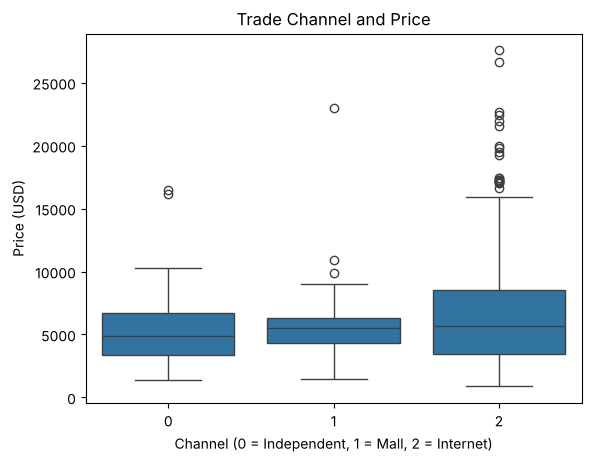

In [11]:
# instantiating a boxplot for channel and price
sns.boxplot(x      = 'channel' , # categorical data for subsets
            y      = 'price'   , # numeric feature on the y-axis
            order  = ['0', '1', '2'],
            data   = diamonds  ) # DataFrame where features exist


# formatting and displaying the plot
plt.title (label  = 'Trade Channel and Price')
plt.xlabel(xlabel = 'Channel (0 = Independent, 1 = Mall, 2 = Internet)')
plt.ylabel(ylabel = 'Price (USD)')
plt.show()

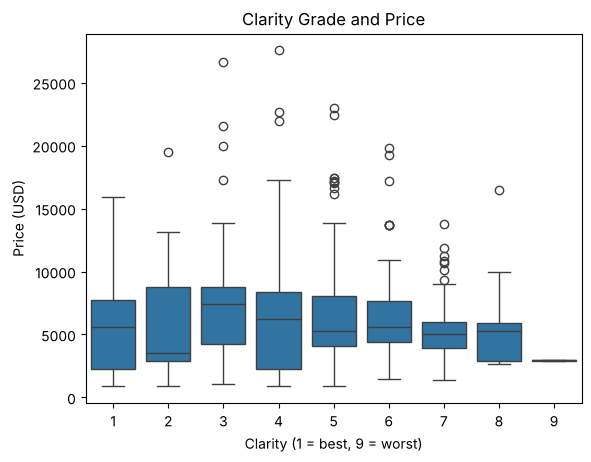

In [12]:
# my own boxplot: does clarity change the price?
sns.boxplot(x    = 'clarity',
            y    = 'price'  ,
            data = diamonds )


# formatting and displaying the plot
plt.title (label  = 'Clarity Grade and Price')
plt.xlabel(xlabel = 'Clarity (1 = best, 9 = worst)')
plt.ylabel(ylabel = 'Price (USD)')
plt.show()

<strong>What the boxplots show:</strong>

* **Channel:** Internet diamonds (2) have the highest median price (about \$5,640) and the widest spread, with many extreme high-price values (the dots above the box). These make up most of the long right tail of price. Independent jewelers (0) have the lowest median (about \$4,900), and Malls (1) are in between (about \$5,500).
* **Clarity:** better clarity (lower number) does **not** clearly mean a higher price on its own. This is because carat weight drives price much more strongly, and it is mixed in with clarity. We need a model with several features to separate these effects.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part II: Linear Correlation</h2>
<h4>a) Generate (Pearson) correlation coefficients for the <em>diamonds</em> dataset. Round your results to two decimal places.</h4>
Running <code>.corr()</code> on the whole DataFrame causes a problem, because <em>channel</em> and <em>store</em> are now text. In Google Colab (pandas 2.x) it raises a <code>ValueError</code> ("could not convert string to float"). The <code>try</code> block below prints the error without stopping the notebook. Some newer pandas versions quietly turn the text back into numbers instead, which is even worse: channel and store are labels, so their "correlations" mean nothing.

In [13]:
# linear (Pearson) correlation
try:
    print(diamonds.corr(method = 'pearson').round(decimals = 2))
except ValueError as error:
    print("Error:", error)

         carat  color  clarity   cut  channel  store  price
carat     1.00   0.22     0.05 -0.24     0.14   0.14   0.88
color     0.22   1.00    -0.06 -0.10    -0.16  -0.10  -0.04
clarity   0.05  -0.06     1.00 -0.09    -0.38  -0.32  -0.10
cut      -0.24  -0.10    -0.09  1.00     0.14   0.09  -0.13
channel   0.14  -0.16    -0.38  0.14     1.00   0.79   0.10
store     0.14  -0.10    -0.32  0.09     0.79   1.00   0.08
price     0.88  -0.04    -0.10 -0.13     0.10   0.08   1.00


<h4>b) Fix the code with the <code>numeric_only</code> argument, so only numeric columns are used.</h4>

In [14]:
# linear (Pearson) correlation
diamonds.corr(method       = 'pearson',
              numeric_only = True).round(decimals = 2)

,carat,color,clarity,cut,price
carat,1.00,0.22,0.05,-0.24,0.88
color,0.22,1.00,-0.06,-0.10,-0.04
clarity,0.05,-0.06,1.00,-0.09,-0.10
cut,-0.24,-0.10,-0.09,1.00,-0.13
price,0.88,-0.04,-0.10,-0.13,1.00


<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
We can save this as a DataFrame and turn it into a heatmap.
<h4>c) Complete the code below to:</h4>
&#8195;&#8195;i) store the correlation table as an object<br>
&#8195;&#8195;ii) instantiate a heatmap from the stored correlation table

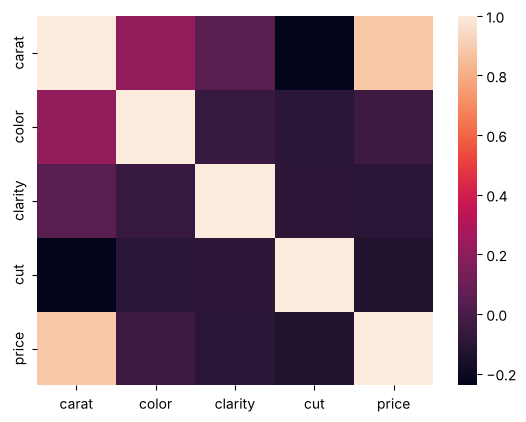

In [15]:
# converting correlation matrix into a DataFrame
diamonds_corr = diamonds.corr(method       = 'pearson',
                              numeric_only = True).round(decimals = 2)

# instantiating a heatmap
sns.heatmap(data = diamonds_corr)


# displaying the plot
plt.show(block = True)

Let's spice up the heatmap.

~~~
         -_
         `-;-_   ,--.__
            `-;-/. ,/\-`.
            _//"\\  '/  |
           /'-   \\ `;\-|    <-- chili pepper
         ,'  ;/   \\  \|;
       ./'  ;'     \\  \(
     ,-" _;'        \\  `
  ,-'_;-"            \
   "'
~~~

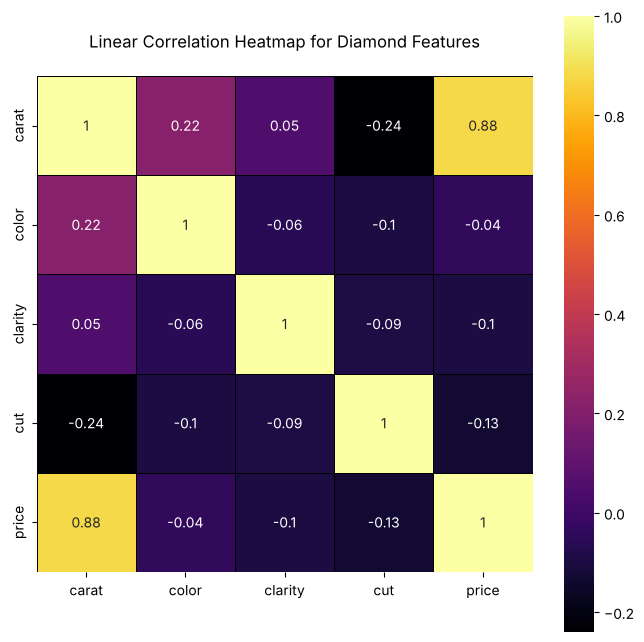

In [16]:
# specifying plot size (making it bigger)
fig, ax = plt.subplots( figsize = (8 , 8) )


# developing a spicy heatmap
sns.heatmap(data       = diamonds_corr, # the correlation matrix
            cmap       = 'inferno'     , # changing to SPICY colors
            square     = True         , # tightening the layout
            annot      = True         , # should there be numbers in the heatmap
            linecolor  = 'black'      , # lines between boxes
            linewidths = 0.5          ) # how thick should the lines be?


# title and displaying the plot
plt.title(label = """
Linear Correlation Heatmap for Diamond Features
""")


# showing the finished product
plt.show(block = True)

That was too spicy! Let's cool things down a bit.
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h4>c) Generate a heatmap with the <em>Blues</em> color scheme.</h4>

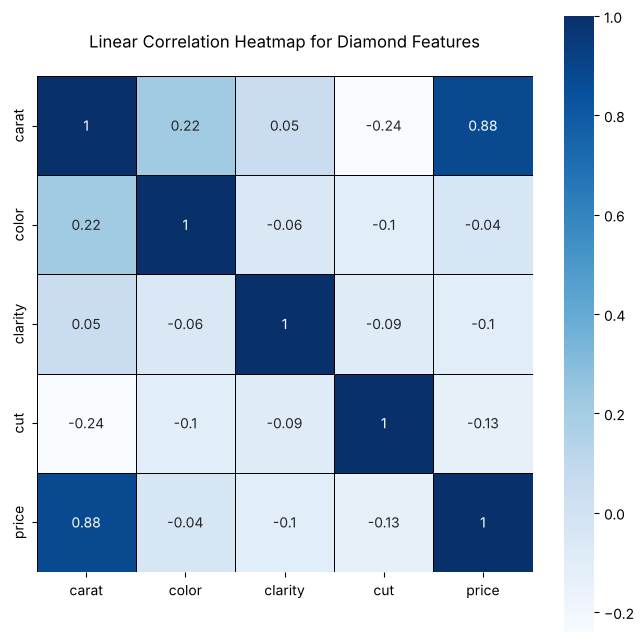

In [17]:
# specifying plot size (making it bigger)
fig, ax = plt.subplots( figsize = (8 , 8) )


# developing a freezing cold heatmap
sns.heatmap(data       = diamonds_corr, # the correlation matrix
            cmap       = 'Blues'       , # changing to COOL colors
            square     = True         , # tightening the layout
            annot      = True         , # should there be numbers in the heatmap
            linecolor  = 'black'      , # lines between boxes
            linewidths = 0.5          ) # how thick should the lines be?


# title and displaying the plot
plt.title(label = """
Linear Correlation Heatmap for Diamond Features
""")


# showing the finished product
plt.show(block = True)

Now it looks freezing! Let's mix hot and cold.
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h4>d) Generate a heatmap with the <em>coolwarm</em> color scheme.</h4>

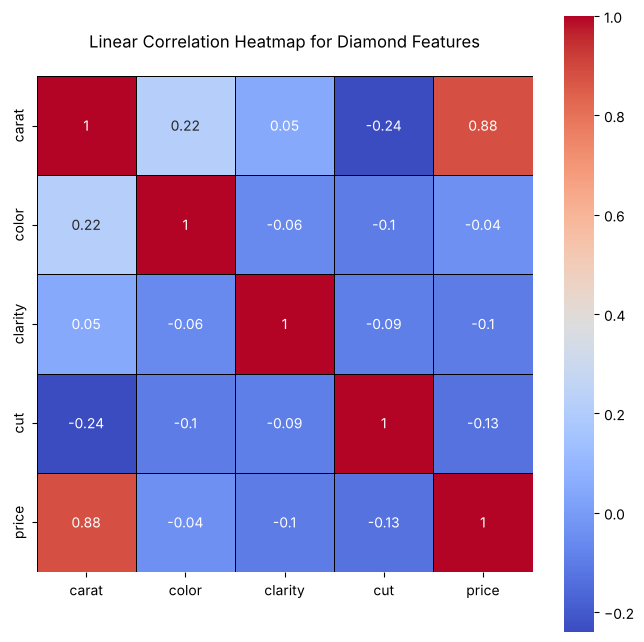

In [18]:
# specifying plot size (making it bigger)
fig, ax = plt.subplots( figsize = (8 , 8) )


# developing a coolwarm heatmap
sns.heatmap(data       = diamonds_corr, # the correlation matrix
            cmap       = 'coolwarm'    , # changing to MEDIUM colors
            square     = True         , # tightening the layout
            annot      = True         , # should there be numbers in the heatmap
            linecolor  = 'black'      , # lines between boxes
            linewidths = 0.5          ) # how thick should the lines be?


# title and displaying the plot
plt.title(label = """
Linear Correlation Heatmap for Diamond Features
""")


# showing the finished product
plt.show(block = True)

<strong>Reading the heatmap:</strong>

* **Carat and price** have a very strong positive correlation (**0.88**). Heavier diamonds cost more.
* **Color, clarity and cut** have almost no linear correlation with price on their own (between -0.13 and -0.04).
* Color and cut are correlated with **carat** (0.22 and -0.24). Bigger stones in this dataset tend to have slightly worse color grades and are less often Ideal cut. Because carat drives price so strongly, the effect of color and cut is hidden when we look at them one at a time.
* `coolwarm` is the best choice of the three schemes for correlations. It shows positive values in red, negative values in blue and values near zero in white, so the sign of each correlation is easy to see.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part III: Scatter and Linear Model Plots</h2>
Scatter plots show the relationship between two variables. Linear model plots add a trend line. The square of the correlation coefficient is called <strong>R-Squared</strong>.<br><br>
The code below draws a scatter plot between <em>carat</em> and <em>price</em>.

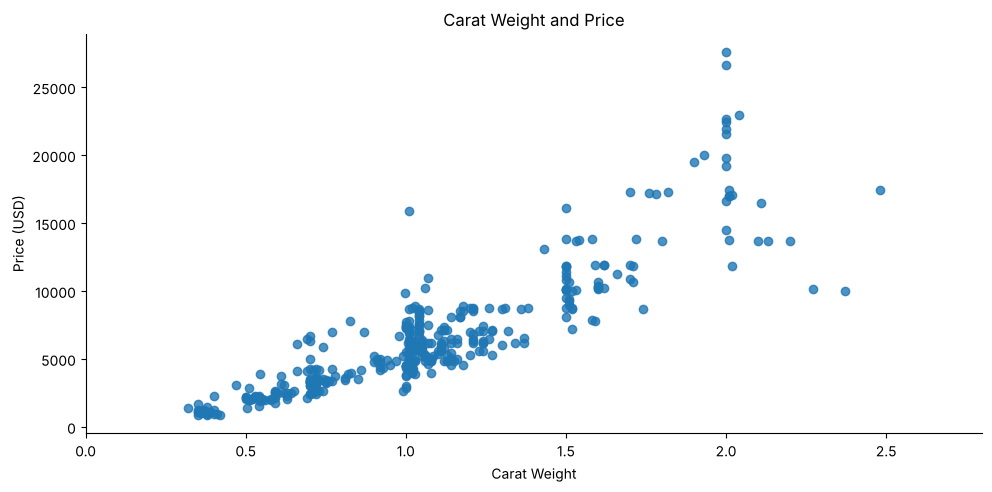

In [19]:
# instantiating a scatter plot for carat and price
sns.lmplot(x          = 'carat' , # x-axis feature
           y          = 'price' , # y-axis feature
           hue        = None    , # categorical data for subsets
           scatter    = True    , # renders a scatter plot
           fit_reg    = False   , # renders a regression line
           aspect     = 2       , # aspect ratio for plot
           data       = diamonds) # DataFrame where features exist


# formatting and displaying the plot
plt.title       (label  = 'Carat Weight and Price')
plt.xlabel      (xlabel = 'Carat Weight'          )
plt.ylabel      (ylabel = 'Price (USD)'           )
plt.xlim        (left   = 0, right = 2.8          )
plt.tight_layout(pad    = 1.0                     )
plt.show        (block  = True                    )

<h4>a) Change the value of the <em>fit_reg</em> argument to True.</h4>

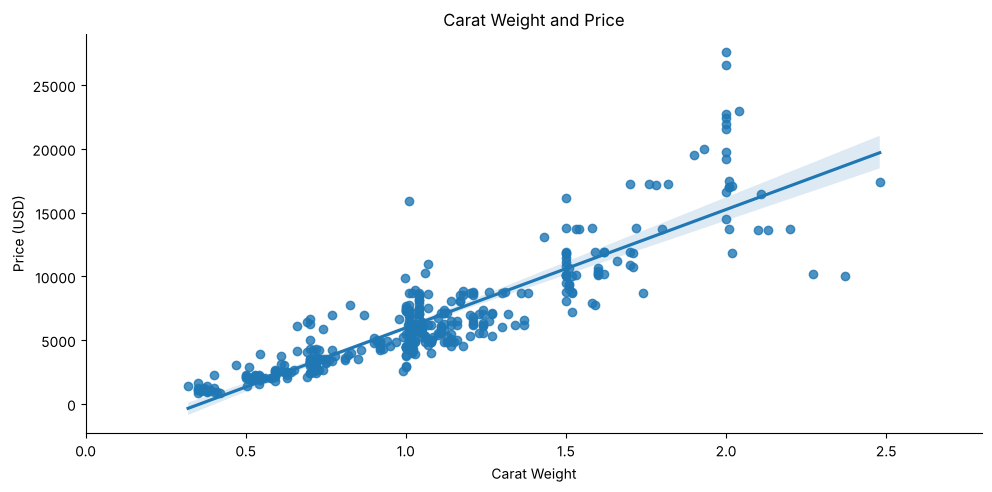

In [20]:
# instantiating an lmplot for carat and price
sns.lmplot(x          = 'carat' , # x-axis feature
           y          = 'price' , # y-axis feature
           hue        = None    , # categorical data for subsets
           scatter    = True    , # renders a scatter plot
           fit_reg    = True    , # renders a regression line
           aspect     = 2       , # aspect ratio for plot
           data       = diamonds) # DataFrame where features exist


# formatting and displaying the plot
plt.title       (label  = 'Carat Weight and Price')
plt.xlabel      (xlabel = 'Carat Weight'          )
plt.ylabel      (ylabel = 'Price (USD)'           )
plt.xlim        (left   = 0, right = 2.8          )
plt.tight_layout(pad    = 1.0                     )
plt.show        (block  = True                    )

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
The documentation says that "diamonds are sized in one-quarter increments", but the trend between price and carat does not seem to change at each 0.25 step. More likely, when a diamond is sold it is replaced with one of similar weight. The trend does get **steeper after about 1.50 carats**, and it seems to slope **down after 2.00 carats** (though there are very few stones above 2.00).

The code below creates a categorical variable for half-carat groups and draws vertical lines at each half carat.

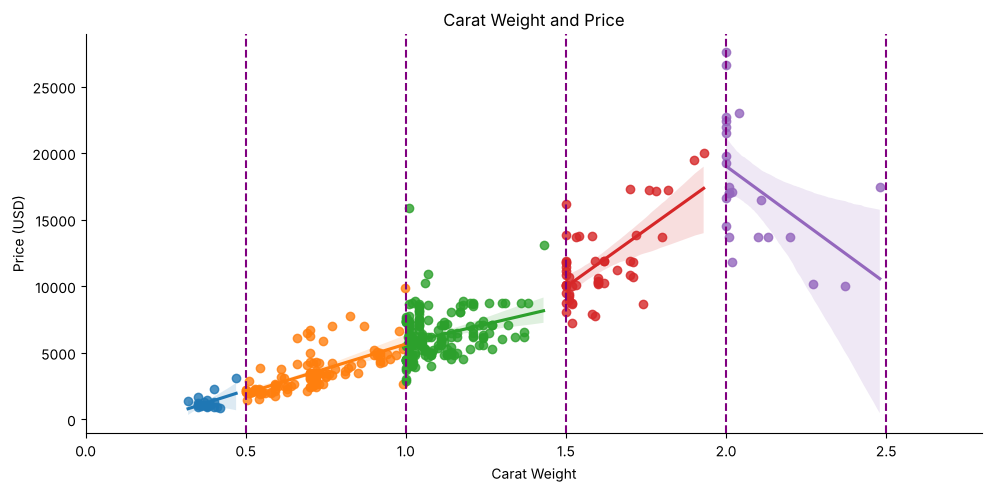

In [21]:
# creating a dummy column in the diamonds DataFrame
diamonds['Carat Size'] = ''


# for loop with iterrows() <-- one of the most useful methods for DataFrames
for index, col in diamonds.iterrows():


    # conditionals to change the values in the new column
    if diamonds.loc[index, 'carat'] < 0.5:
        diamonds.loc[index, 'Carat Size'] = '[0.0, 0.5)'


    elif diamonds.loc[index, 'carat'] < 1.0:
        diamonds.loc[index, 'Carat Size'] = '[0.5 - 1.0)'


    elif diamonds.loc[index, 'carat'] < 1.5:
        diamonds.loc[index, 'Carat Size'] = '[1.0 - 1.5)'


    elif diamonds.loc[index, 'carat'] < 2.0:
        diamonds.loc[index, 'Carat Size'] = '[1.5 - 2.0)'


    elif diamonds.loc[index, 'carat'] >= 2.0:
        diamonds.loc[index, 'Carat Size'] = '[2.0 - inf)'


    # safety net
    else:
        diamonds.loc[index, 'Carat Size'] = 'error'


# instantiating an lmplot for carat and price
sns.lmplot(x          = 'carat'     ,
           y          = 'price'     ,
           hue        = 'Carat Size', # categorical data for subsets
           legend     = False       , # supressing the legend
           scatter    = True        ,
           fit_reg    = True        ,
           aspect     = 2           ,
           data       = diamonds    )


# developing vertical axis lines
value = 0.50

while value < 3.00:

    # making a vertical line
    plt.axvline(x = value, color = "purple", linestyle = '--')

    # incrementing value in half-carat increments
    value += 0.50


# formatting and displaying the plot
plt.title       (label  = 'Carat Weight and Price')
plt.xlabel      (xlabel = 'Carat Weight'          )
plt.ylabel      (ylabel = 'Price (USD)'           )
plt.xlim        (left   = 0, right = 2.8          )
plt.tight_layout(pad    = 1.0                     )
plt.show        (block  = True                    )

In [22]:
# how many diamonds are in each carat group?
diamonds['Carat Size'].value_counts().sort_index()

Carat Size
[0.0, 0.5)      24
[0.5 - 1.0)    122
[1.0 - 1.5)    187
[1.5 - 2.0)     52
[2.0 - inf)     24
Name: count, dtype: int64

<strong>Observation:</strong> each half-carat group has its own slope, and the slope gets steeper as carat weight goes up. Price does not grow in a straight line with carat. Each extra carat adds more to the price for big stones than for small ones. The **[2.0 - inf)** group has only a handful of diamonds, so its downward slope should not be trusted.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part IV: Base Modeling</h2>
A <strong>base model</strong> is a simple, interpretable model built with the available features in their original form. Base models:

* act as a common-sense test of our data, assumptions and domain knowledge;
* give a benchmark to compare more complex models against;
* use features that follow the assumptions of the model type.

<div align="center">Predictive modeling is the process of taking known results and developing<br>a model that can predict values for new occurrences.</div><br>
<font style=color:red><strong>Predictive modeling is NOT about being right. It is about being less wrong.</strong></font>
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h4>a) Analyze the correlations with <em>price</em>.</h4>
Which feature has the strongest correlation with price?

In [23]:
# developing a correlation matrix
diamonds_corr = diamonds.corr(method       = 'pearson',
                              numeric_only = True)


# filtering results to show correlations with price
diamonds_corr.loc[ : , 'price'].round(decimals = 2).sort_values(ascending = False)

price      1.00
carat      0.88
color     -0.04
clarity   -0.10
cut       -0.13
Name: price, dtype: float64

<strong>Answer:</strong> **carat** has by far the strongest correlation with price (**0.88**). Cut (-0.13), clarity (-0.10) and color (-0.04) are all weak on their own.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h3>Building A Base Model</h3>
The following code is the basic framework for a predictive model with <a href="https://www.statsmodels.org/stable/index.html">statsmodels</a>.

In [24]:
# Step 1: INSTANTIATE a model object
lm_base = smf.ols(formula = """price ~ carat""",
                  data    = diamonds)


# Step 2: FIT the data into the model object
results_base = lm_base.fit()


# Step 3: analyze the SUMMARY output
print(results_base.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.772
Model:                            OLS   Adj. R-squared:                  0.772
Method:                 Least Squares   F-statistic:                     1382.
Date:                Fri, 06 Nov 2026   Prob (F-statistic):          6.45e-133
Time:                        16:00:06   Log-Likelihood:                -3709.7
No. Observations:                 409   AIC:                             7423.
Df Residuals:                     407   BIC:                             7431.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -3312.9131    283.527    -11.685      0.0

<strong>Reading the base model:</strong>

* **R-squared = 0.772**. Carat alone explains about 77% of the variation in price. This matches the correlation: 0.88² ≈ 0.77.
* **carat coefficient ≈ \$9,282**. Each extra carat adds about that much to the predicted price.
* **Intercept ≈ -\$3,313**. This is the predicted price of a 0-carat diamond. It makes no real-world sense, but it is needed for the line to fit the data.
* Both p-values are 0.000, so carat is clearly significant.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part V: Case Study - Pricing the "Best" Diamond on a Budget</h2>

<strong>a) Develop an optimal pricing model using more than one x-feature.</strong><br>
Find the combination of x-features that maximizes adjusted R-squared, where all coefficients have p-values ≤ 0.05.<br><br>
<strong>Approach (backward selection):</strong> start with all features, check the p-values, and remove insignificant features one at a time.

<strong>Model 1: all four diamond characteristics</strong> (carat, color, clarity, cut)

In [25]:
# Step 1: INSTANTIATE a model object
lm_full = smf.ols(formula =  """price ~ carat   +
                                        color   +
                                        clarity +
                                        cut""",
                  data = diamonds)


# Step 2: FIT the data into the model object
results_full = lm_full.fit()


# Step 3: analyze the SUMMARY output
print(results_full.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.861
Model:                            OLS   Adj. R-squared:                  0.860
Method:                 Least Squares   F-statistic:                     628.0
Date:                Fri, 06 Nov 2026   Prob (F-statistic):          6.91e-172
Time:                        16:00:06   Log-Likelihood:                -3608.2
No. Observations:                 409   AIC:                             7226.
Df Residuals:                     404   BIC:                             7246.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    530.4921    403.197      1.316      0.1

All four features are significant (p ≤ 0.05), and adjusted R-squared rises from 0.772 to **0.860**.
Only the **intercept** has a p-value above 0.05 (0.189). The intercept is not a feature, so the model still meets the rule, but it shows that something is missing from the model.

From Part I we know that price also changes by **channel** (the boxplot). Next, we add channel as a categorical feature. `C(channel)` tells statsmodels to turn it into dummy variables, using channel 0 (Independent) as the baseline.

<strong>Model 2: adding the trade channel</strong>

In [26]:
# Step 1: INSTANTIATE a model object
lm_best = smf.ols(formula =  """price ~ carat      +
                                        color      +
                                        clarity    +
                                        cut        +
                                        C(channel)""",
                  data = diamonds)


# Step 2: FIT the data into the model object
results = lm_best.fit()


# Step 3: analyze the SUMMARY output
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.891
Model:                            OLS   Adj. R-squared:                  0.890
Method:                 Least Squares   F-statistic:                     549.3
Date:                Fri, 06 Nov 2026   Prob (F-statistic):          3.18e-190
Time:                        16:00:06   Log-Likelihood:                -3558.6
No. Observations:                 409   AIC:                             7131.
Df Residuals:                     402   BIC:                             7159.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept        3653.6607    480.149     

<strong>Model 3 (checked, then rejected): using store instead of channel</strong>

In [27]:
# store gives a higher adjusted R-squared, but are all coefficients significant?
lm_store = smf.ols(formula = """price ~ carat + color + clarity + cut + C(store)""",
                   data    = diamonds)

results_store = lm_store.fit()


# showing only the p-values that break the 0.05 rule
pvalues = results_store.pvalues.round(decimals = 3)
print("Adjusted R-squared:", round(results_store.rsquared_adj, 4))
print("\nCoefficients with p-value > 0.05:")
print(pvalues[ pvalues > 0.05 ])

Adjusted R-squared: 0.9066

Coefficients with p-value > 0.05:
C(store)[T.7]    0.343
C(store)[T.8]    0.412
dtype: float64


In [28]:
# comparing all candidate models side by side
comparison = pd.DataFrame({
    'Model'              : ['Base: carat',
                            'Model 1: carat + color + clarity + cut',
                            'Model 2: Model 1 + channel',
                            'Model 3: Model 1 + store'],
    'Adjusted R-squared' : [results_base.rsquared_adj,
                            results_full.rsquared_adj,
                            results.rsquared_adj,
                            results_store.rsquared_adj],
    # highest p-value among the x-features (the intercept is not a feature)
    'Max feature p-value': [results_base.pvalues.drop('Intercept').max(),
                            results_full.pvalues.drop('Intercept').max(),
                            results.pvalues.drop('Intercept').max(),
                            results_store.pvalues.drop('Intercept').max()],
    'Intercept p-value'  : [results_base.pvalues['Intercept'],
                            results_full.pvalues['Intercept'],
                            results.pvalues['Intercept'],
                            results_store.pvalues['Intercept']]
})

comparison['All features p <= 0.05'] = comparison['Max feature p-value'] <= 0.05
comparison.round(decimals = 4)

,Model,Adjusted R-squared,Max feature p-value,Intercept p-value,All features p <= 0.05
0,Base: carat,0.7719,0.0000,0.000,True
1,Model 1: carat + color + clarity + cut,0.8601,0.0015,0.189,True
2,Model 2: Model 1 + channel,0.8897,0.0001,0.000,True
3,Model 3: Model 1 + store,0.9066,0.4118,0.000,False


<strong>Selected model: Model 2</strong> (carat + color + clarity + cut + channel)

* It has the **highest adjusted R-squared (0.890)** of the models where **every coefficient, including the intercept, has p ≤ 0.05**.
* Model 3 (store) has a slightly higher adjusted R-squared (0.907), but stores 7 and 8 are **not significant** (p > 0.05). Script 02 also showed that 9 of the 11 stores have fewer than 30 diamonds, so store-level coefficients are not reliable. Model 3 breaks the rule and is rejected.

<strong>Interpreting the coefficients (holding the other features constant):</strong>

| Feature | Coefficient | Meaning |
|---|---|---|
| carat | +\$10,626 | each extra carat adds about this much to the price |
| color | -\$731 | each step down the color scale (worse color) lowers the price by this much |
| clarity | -\$674 | each step down the clarity scale (worse clarity) lowers the price by this much |
| cut | +\$821 | an Ideal cut changes the price by this much |
| channel 1 (Mall) | -\$1,234 | compared with an Independent jeweler |
| channel 2 (Internet) | -\$2,637 | compared with an Independent jeweler |

<strong>Two interesting findings:</strong>

* **Cut changes sign.** On its own, cut has a *negative* correlation with price (-0.13). In the model, an Ideal cut *adds* about \$821. The reason is that Ideal-cut stones in this dataset tend to be smaller (correlation with carat is -0.24). Once carat is held constant, a better cut is worth more, which is what we would expect.
* **Channel also changes direction.** In the boxplot, Internet diamonds looked the most expensive. In the model, for the **same** carat, color, clarity and cut, an Internet diamond is about **\$2,637 cheaper** and a Mall diamond about **\$1,234 cheaper** than one from an Independent jeweler. The boxplot was misleading because each channel sells a different mix of diamonds. This is a good example of why a model with several features is needed.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<strong>b) Apply your optimal pricing model to the top five diamonds from <em>Finding the "Best" Diamond on a Budget</em> in Script 01.</strong><br>
How well did the model predict? Were you surprised by the results?

In [29]:
# code from Finding the "Best" Diamond on a Budget
best_diamonds = diamonds[ (diamonds['price']   <= 5795) ]\
                        [ (diamonds['carat']   >= 0.9 ) ]\
                        [ (diamonds['color']   <= 4   ) ]\
                        [ (diamonds['clarity'] <= 5   ) ]\
                        [ (diamonds['cut']     <= 1   ) ].copy()


# selecting predictor data (x_data)
predictors = ['carat', 'color', 'clarity', 'cut', 'channel']


# predicting on top diamonds with the optimal model (Model 2)
best_diamonds['y_hat'] = results.predict(best_diamonds[predictors]).astype(int)


# predictions from Model 1 (no channel) for comparison
best_diamonds['y_hat_model_1'] = results_full.predict(best_diamonds[predictors]).astype(int)


# how far off is the optimal model? (positive = the diamond costs LESS than predicted)
best_diamonds['savings'] = best_diamonds['y_hat'] - best_diamonds['price']


# checking results
best_diamonds[ ['carat', 'color', 'clarity', 'cut', 'channel', 'store',
                'price', 'y_hat', 'y_hat_model_1', 'savings'] ]

,carat,color,clarity,cut,channel,store,price,y_hat,y_hat_model_1,savings
64,1.14,4,4,0,1,2,5472,8910,7748,3438
66,1.01,2,5,0,1,6,5500,8317,7229,2817
214,0.91,2,5,0,2,10,4841,5853,6218,1012
232,0.91,1,5,0,2,10,5030,6584,6841,1554
243,1.01,4,5,0,2,11,5550,5453,5981,-97


In [30]:
# summary of prediction errors on the top five
error     = best_diamonds['y_hat'] - best_diamonds['price']
error_pct = (error.abs() / best_diamonds['price'] * 100)

print(f"Average absolute error : ${error.abs().mean():,.0f}")
print(f"Average absolute error : {error_pct.mean():.1f}% of the actual price")
print(f"Model RMSE (all data)  : ${results.mse_resid ** 0.5:,.0f}")

Average absolute error : $1,784
Average absolute error : 33.5% of the actual price
Model RMSE (all data)  : $1,466


<strong>How well did the model predict?</strong>

| Diamond | Channel | Actual price | Predicted (Model 2) | Difference |
|---|---|---|---|---|
| 1.14 ct, color 4, clarity 4 | Mall | \$5,472 | \$8,910 | \$3,438 cheaper than predicted |
| 1.01 ct, color 2, clarity 5 | Mall | \$5,500 | \$8,317 | \$2,817 cheaper than predicted |
| 0.91 ct, color 2, clarity 5 | Internet | \$4,841 | \$5,853 | \$1,012 cheaper than predicted |
| 0.91 ct, color 1, clarity 5 | Internet | \$5,030 | \$6,584 | \$1,554 cheaper than predicted |
| 1.01 ct, color 4, clarity 5 | Internet | \$5,550 | \$5,453 | \$97 more than predicted |

* The average error is about **\$1,780 (about 34% of the actual price)**. That is larger than the model's typical error on the whole dataset (RMSE ≈ \$1,466). For one diamond (the 1.01 ct online stone) the model is almost exact. For the two mall diamonds it is far off.
* **Was I surprised?** Partly. The model says **4 of the 5 diamonds are worth more than they cost**, and Model 1 (without channel) says the same for all 5. At first this looks like a weak model, but it makes sense: in Script 01 we *chose* these diamonds because they have good features **and** a low price. A filter like that picks out bargains, so the actual prices are naturally below the model's average prediction. This is called **selection bias**.
* **The two mall diamonds are the biggest surprise.** They cost about \$3,000 less than the model expects for a mall stone of that quality. Either they are real bargains, or there is something the data does not capture (such as a weaker certificate, the exact cut grade, or a sale price). A buyer should check them in person before buying.
* **Business conclusion:** the 1.14 carat mall diamond (\$5,472) is still the top pick. It is the biggest stone, and the model says it has the largest discount compared with its expected value.

~~~
                       ________
               o      |   __   |
                 \_ O |  |__|  |
              ____/ \ |___WW___|
              __/   /     ||
                          ||
                          ||
           _______________||________________

   Slam Dunk!
~~~

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Bonus: Violin and Hybrid Plots</h2>
Here we assume we have enough data for each store and channel to avoid bias from the categorical labels.<br><br>
The class version uses <code>diamonds_labeled.xlsx</code>, where channel is stored as words. We only have <code>diamonds.xlsx</code>, so the code below adds the labels ourselves.

In [31]:
# adding readable labels for channel (same as diamonds_labeled.xlsx)
channel_names = {'0' : 'Independent',
                 '1' : 'Mall',
                 '2' : 'Internet'}

diamonds['channel_name'] = diamonds['channel'].map(channel_names)


# now the subset from the class notebook works
mall_channel = diamonds[ (diamonds.loc[ : , 'channel_name'] == 'Mall') ]
print("Diamonds in the mall channel:", len(mall_channel))

Diamonds in the mall channel: 48


<strong>Violin plots</strong> combine a boxplot (inside) and a smoothed histogram (outside). With `split = True` they show two distributions side by side, based on a binary variable (here, cut).

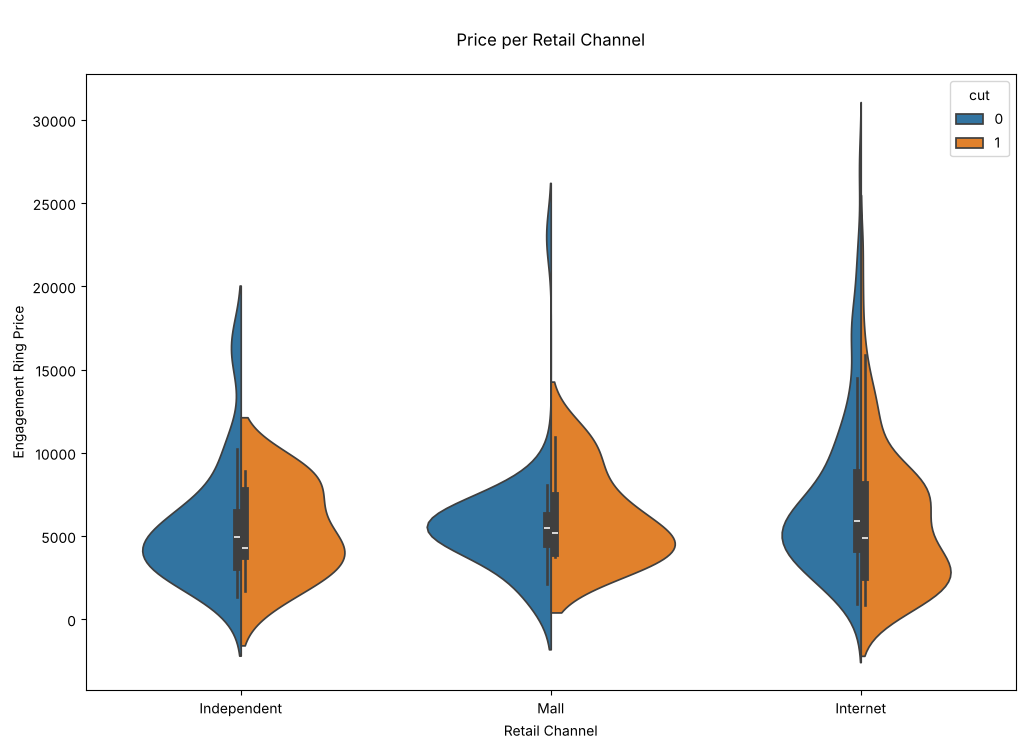

In [32]:
# specifying plot size (making it bigger)
fig, ax = plt.subplots( figsize = (12 , 8) )


# violin plots
sns.violinplot(x      = 'channel_name',
               y      = 'price'       ,
               hue    = 'cut'         ,
               split  = True          ,
               data   = diamonds      ,
               orient = 'v'           )


# formatting and displaying the plot
plt.title(label = """
Price per Retail Channel
""")
plt.xlabel(xlabel = 'Retail Channel'       )
plt.ylabel(ylabel = 'Engagement Ring Price')
plt.show  (block  = True                   )

Any plot that uses a kernel density estimate (KDE) is making assumptions about the shape of the distribution, even with very few samples. <font style=color:red><strong>Be careful! Check your sample sizes before concluding on any findings!</strong></font><br><br>
A <strong>strip plot</strong> shows every single data point. Combined with a violin plot, it shows whether the KDE is backed up by enough data.

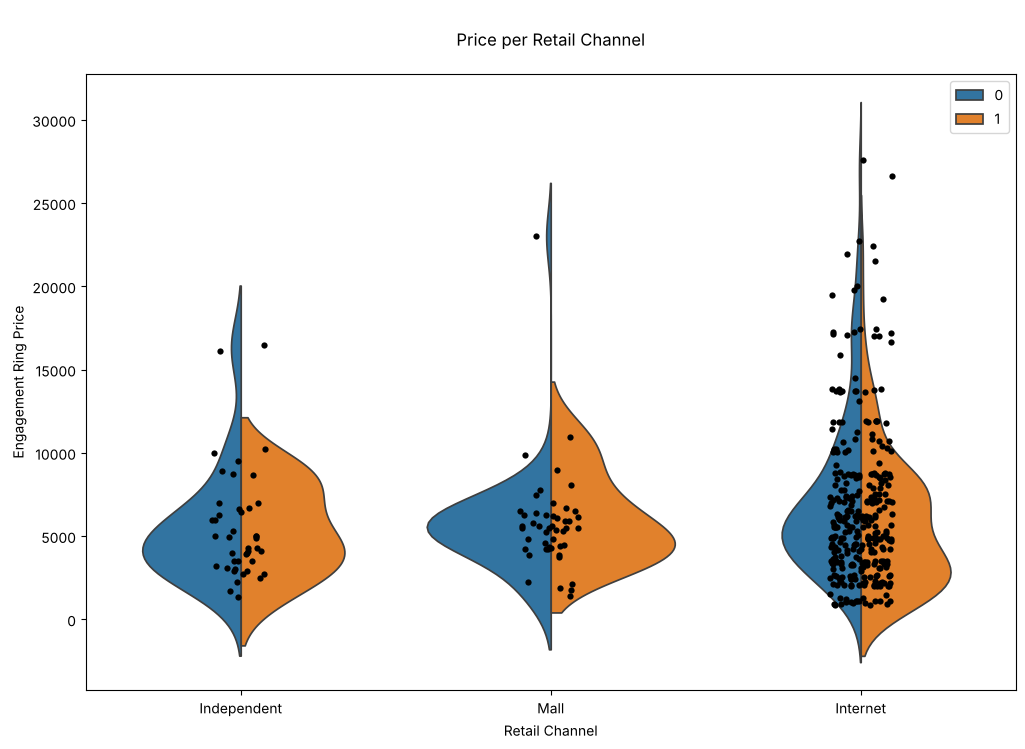

In [33]:
# specifying plot size (making it bigger)
fig, ax = plt.subplots( figsize = (12 , 8) )


# outline with a violin plot
sns.violinplot(x      = 'channel_name',
               y      = 'price'       ,
               hue    = 'cut'         ,
               split  = True          ,
               data   = diamonds      ,
               orient = 'v'           ,
               inner  = None          )


# embedding a stripplot plot
sns.stripplot(x      = 'channel_name',
              y      = 'price'       ,
              data   = diamonds      ,
              size   = 4.5           ,
              orient = 'v'           ,
              color  = 'black'       )


plt.title(label = """
Price per Retail Channel
""")
plt.xlabel(xlabel = 'Retail Channel'       )
plt.ylabel(ylabel = 'Engagement Ring Price')
plt.show  (block  = True                   )

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h4>a) Analyze each store in the <em>Online</em> channel.</h4>
Sample sizes for stores in the Online channel are large enough for a store-level analysis. Do the stores in this channel use similar pricing strategies?<br>
<strong>Hint:</strong> This channel is labeled as <em>2</em> in the dataset.

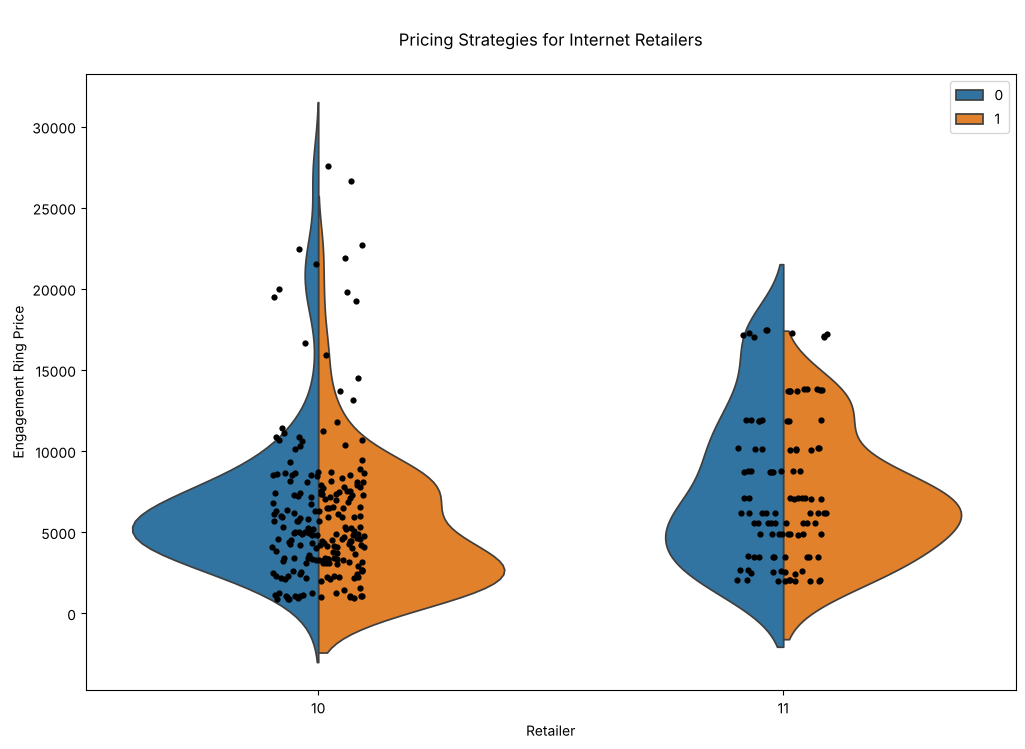

In [34]:
# specifying plot size (making it bigger)
fig, ax = plt.subplots( figsize = (12 , 8) )


# subsetting to the internet channel
internet = diamonds[ diamonds.loc[ : , 'channel' ] == '2' ]


# outline with a violin plot
sns.violinplot(x      = 'store'  ,
               y      = 'price'  ,
               hue    = 'cut'    ,
               split  = True     ,
               data   = internet ,
               orient = 'v'      ,
               inner  = None     )


# embedding a stripplot plot
sns.stripplot(x      = 'store'  ,
              y      = 'price'  ,
              data   = internet ,
              size   = 4.5      ,
              orient = 'v'      ,
              color  = 'black'  )


# title and labels
plt.title(label   = """
Pricing Strategies for Internet Retailers
"""                                        )
plt.xlabel(xlabel = 'Retailer'             )
plt.ylabel(ylabel = 'Engagement Ring Price')
plt.show  (block  = True                   )

In [35]:
# backing up the plot with numbers
internet.groupby(['store', 'cut'])['price'].describe()[ ['count', 'mean', '50%', 'max'] ].round(0)

count    mean     50%      max
store cut                                
10    0    108.0  6959.0  5694.0  27575.0
      1    103.0  5402.0  4338.0  22431.0
11    0     77.0  8027.0  6200.0  17450.0
      1     30.0  7042.0  6630.0  13820.0

In [36]:
# do the two stores sell the same kind of diamonds?
internet.groupby('store')[ ['carat', 'color', 'clarity', 'cut'] ].mean().round(2)

,carat,color,clarity,cut
store,,,,
10,1.01,3.99,4.75,0.49
11,1.23,4.29,4.74,0.28


In [37]:
# comparing the stores on EQUAL diamonds: price model inside the internet channel
results_internet = smf.ols(formula = """price ~ carat + color + clarity + cut + C(store)""",
                           data    = internet).fit()

print(results_internet.params.round(0))
print("\np-value for store 11:", round(results_internet.pvalues['C(store)[T.11]'], 3))

Intercept          1294.0
C(store)[T.11]     -487.0
carat             11052.0
color              -807.0
clarity            -707.0
cut                 552.0
dtype: float64

p-value for store 11: 0.002


<strong>Answer:</strong> **Partly similar, but not the same.**

* **What is similar:** in both stores, carat, color, clarity and cut drive the price in the same direction, and both stores sell some very expensive stones (store 10 up to \$27,575, store 11 up to \$17,450).
* **What is different:**
  * **Product mix:** store 10 sells many more Ideal cuts (103 of 211, about 49%) than store 11 (30 of 107, about 28%). Store 11 sells bigger stones on average (1.23 vs 1.01 carats), which explains why its raw prices look higher.
  * **Price level:** once we compare *equal* diamonds (same carat, color, clarity and cut), store 11 is about **\$487 cheaper** than store 10, and this difference is significant (p = 0.002).
* In both stores the **Ideal-cut** violins sit lower than the Not Ideal ones. This does not mean that Ideal cuts are cheaper. It is the same effect as before: Ideal-cut stones tend to be smaller.

**Conclusion:** the two online stores price diamonds using the same factors, but with **different strategies**. Store 10 offers a wider range and more Ideal cuts, while store 11 focuses on bigger stones at a slightly lower price for the same quality.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Bonus: statsmodels OLS Study Sheet</h2>
The class version shows two images here. Below is the same information as a table.

| Output | What it means |
|---|---|
| **Dep. Variable** | the y-variable we predict (price) |
| **No. Observations** | number of rows used to fit the model |
| **Df Model** | number of x-features (dummy variables count separately) |
| **R-squared** | share of the variation in y explained by the model (0 to 1) |
| **Adj. R-squared** | R-squared with a penalty for each extra feature. Use it to compare models with different numbers of features |
| **F-statistic / Prob (F-statistic)** | tests whether the model as a whole is better than no model. A small Prob means yes |
| **AIC / BIC** | model-fit measures that penalize complexity. Lower is better |
| **coef** | change in y for a one-unit increase in x, holding the other features constant |
| **std err** | uncertainty of the coefficient |
| **t** | coef ÷ std err |
| **P>\|t\|** | p-value. ≤ 0.05 means the feature is statistically significant |
| **[0.025  0.975]** | 95% confidence interval for the coefficient. If it includes 0, the feature is not significant |
| **Omnibus / Jarque-Bera** | tests whether the errors (residuals) are normally distributed. Small Prob means they are not |
| **Skew / Kurtosis** | shape of the residuals (0 and 3 for a normal distribution) |
| **Durbin-Watson** | checks if errors are correlated with each other. About 2 is good |
| **Cond. No.** | a large value warns of multicollinearity (x-features strongly related to each other) |